# LammpsEngine walkthrough

`LammpsEngine` implements the `pyiron_workflow_atomistics` engine protocol, so
LAMMPS is driven through the same `calculate(structure=..., engine=...)` node as
any other engine. `calculate` is a `flowrep` node: call it directly to get the
`EngineOutput` back as a plain Python value, or run it through
`pyiron_workflow` (`pwf.node(calculate).run(...)` / `pwf.run(...)`) to get a
`Run` record with `.outputs`.

This notebook needs a LAMMPS executable (`lmp`) with the `MANYBODY` package and
`matplotlib` for the plots. It uses the `Al-Fe.eam.fs` potential next to it, so
run it from the `notebooks/` directory (Jupyter does this by default). All
LAMMPS files go into a temporary directory that the last cell deletes. Note
that `LammpsEngine`'s default `input_script_pair_style` is `"grace"`, so
classical potentials must set it (here `"eam/fs"`).

Conventions of the returned `EngineOutput`:

- `final_energy` / `energies`: the potential energy in eV (consistent with the
  forces; for MD it excludes the kinetic energy).
- `final_stress` / `stresses`: the LAMMPS pressure tensor as parsed by
  `lammpsparser`, in GPa with compression positive.
- `n_ionic_steps`: the last LAMMPS step number (an `int`).
- `structures` / `energies`: one entry per thermo output step, including the
  last step, so they have the same length and `final_structure` belongs to
  `final_energy`.
- `final_forces`, `final_stress` and `final_structure`: in the frame and with
  the lattice vectors of the input structure, also for cells LAMMPS has to
  rotate (e.g. primitive or sheared cells).
- `converged`: LAMMPS finished, and a minimisation stopped on its energy or
  force tolerance (not on `max_iterations` / `max_evaluations`). These are
  LAMMPS' own tolerances, passed through unchanged:
  `energy_convergence_tolerance` is LAMMPS' relative (dimensionless) `etol`,
  `force_convergence_tolerance` bounds the 2-norm of the global force vector.

In [1]:
import pathlib
import shutil
import tempfile

import matplotlib.pyplot as plt
from ase.build import bulk

import pyiron_workflow as pwf
from pyiron_workflow_atomistics.engine import (
    CalcInputMD,
    CalcInputMinimize,
    CalcInputStatic,
    calculate,
)
from pyiron_workflow_lammps.engine import LammpsEngine

# The bundled potential, next to this notebook. LAMMPS runs in its own working
# directory, so pass it an absolute path.
EAM_POTENTIAL_PATH = pathlib.Path("Al-Fe.eam.fs").resolve()
assert EAM_POTENTIAL_PATH.is_file(), "run this notebook from the notebooks/ directory"
EAM_POTENTIAL_PATH = str(EAM_POTENTIAL_PATH)

# Scratch space for the LAMMPS runs; deleted in the last cell.
WORKDIR = pathlib.Path(tempfile.mkdtemp(prefix="pwl_example_"))

In [2]:
lmp_cmd = "lmp"

# Static LAMMPS calculation

Calling `calculate` directly runs the calculation and returns the
`EngineOutput`. A static calculation is LAMMPS `run 0`: one energy/force
evaluation at step 0.

In [3]:
structure = bulk("Fe", cubic=True) * [3, 3, 3]
structure[0].symbol = "Al"

engine = LammpsEngine(
    EngineInput=CalcInputStatic(),
    working_directory=str(WORKDIR / "static"),
    command=f"{lmp_cmd} -in in.lmp -log static.log",
    lammps_log_filepath="static.log",
    input_script_pair_style="eam/fs",
    path_to_model=EAM_POTENTIAL_PATH,
)

out = calculate(structure=structure, engine=engine)
print("E_pot [eV]:", out.final_energy)
print("converged:", out.converged, "| n_ionic_steps:", out.n_ionic_steps)
print("stress [GPa, compression positive]:\n", out.final_stress)

E_pot [eV]: -216.937662272305
converged: True | n_ionic_steps: 0
stress [GPa, compression positive]:
 [[-3.05570837e+00 -2.96077746e-16  1.84945801e-15]
 [-2.96077746e-16 -3.05570837e+00  2.97423632e-17]
 [ 1.84945801e-15  2.97423632e-17 -3.05570837e+00]]


# Minimisation, run as a `pyiron_workflow` node

`pwf.node(calculate).run(...)` executes the same node through
`pyiron_workflow` and returns a `Run`; the output is under
`run.outputs.engine_output`.

finished
E_pot [eV]: -1003.60007932376 | converged: True
last step: 9 | frames: 2 | energies: 2


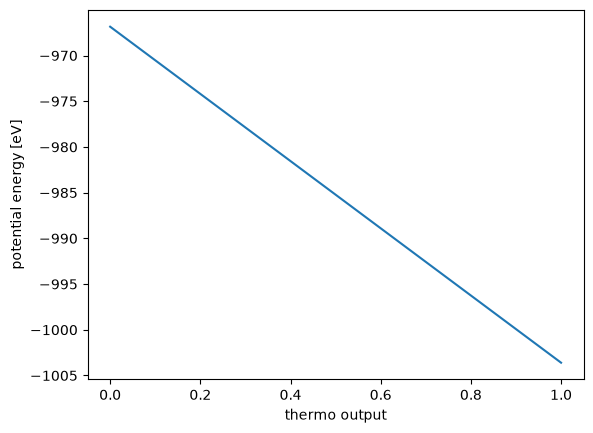

In [4]:
structure = bulk("Fe", cubic=True) * [5, 5, 5]
structure.rattle(0.1, seed=1)
structure[0].symbol = "Al"
structure[10].symbol = "Al"

engine = LammpsEngine(
    EngineInput=CalcInputMinimize(
        energy_convergence_tolerance=1e-5,
        force_convergence_tolerance=1e-5,
        max_iterations=100_000,
    ),
    working_directory=str(WORKDIR / "minimize"),
    command=f"{lmp_cmd} -in in.lmp -log minimize.log",
    lammps_log_filepath="minimize.log",
    input_script_pair_style="eam/fs",
    path_to_model=EAM_POTENTIAL_PATH,
    # Engine-level cap on force/energy evaluations (LAMMPS `minimize` 4th arg),
    # separate from EngineInput.max_iterations.
    max_evaluations=100_000,
)

run = pwf.node(calculate).run(structure=structure, engine=engine)
print(run.status)
minimized = run.outputs.engine_output
print("E_pot [eV]:", minimized.final_energy, "| converged:", minimized.converged)
print(
    "last step:", minimized.n_ionic_steps,
    "| frames:", len(minimized.structures),
    "| energies:", len(minimized.energies),
)

plt.plot(minimized.energies)
plt.xlabel("thermo output")
plt.ylabel("potential energy [eV]")
plt.show()

A minimisation cut off by `max_iterations` still returns its last frame, but
reports `converged=False` (LAMMPS' stopping criterion is "max iterations", not
an energy or force tolerance).

In [5]:
capped_engine = LammpsEngine(
    EngineInput=CalcInputMinimize(
        energy_convergence_tolerance=0.0,
        force_convergence_tolerance=1e-8,
        max_iterations=5,
    ),
    working_directory=str(WORKDIR / "minimize_capped"),
    command=f"{lmp_cmd} -in in.lmp -log minimize.log",
    lammps_log_filepath="minimize.log",
    input_script_pair_style="eam/fs",
    path_to_model=EAM_POTENTIAL_PATH,
)
capped = calculate(structure=structure, engine=capped_engine)
print("converged:", capped.converged, "| last step:", capped.n_ionic_steps)
print("frames:", len(capped.structures), "| energies:", len(capped.energies))

converged: False | last step: 5
frames: 2 | energies: 2


# NVT molecular dynamics (Langevin)

Relax first, then start MD from the relaxed structure. MD times in
`CalcInputMD` are in femtoseconds; the engine converts them to the LAMMPS
`units` time unit (ps for `metal`).

final E_pot [eV]: -992.838445566134 | last step: 1000
frames: 101 | energies: 101


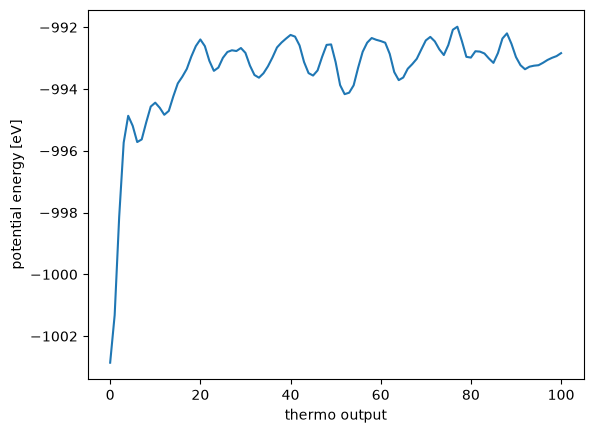

In [6]:
structure = bulk("Fe", cubic=True) * [5, 5, 5]
structure.rattle(0.1, seed=2)

relax_engine = LammpsEngine(
    EngineInput=CalcInputMinimize(
        energy_convergence_tolerance=1e-5,
        force_convergence_tolerance=1e-5,
    ),
    working_directory=str(WORKDIR / "nvt_relax"),
    command=f"{lmp_cmd} -in in.lmp -log minimize.log",
    lammps_log_filepath="minimize.log",
    input_script_pair_style="eam/fs",
    path_to_model=EAM_POTENTIAL_PATH,
)
relaxed = calculate(structure=structure, engine=relax_engine)

md_engine = LammpsEngine(
    EngineInput=CalcInputMD(
        mode="NVT",
        thermostat="langevin",
        temperature=300,
        thermostat_time_constant=100,  # fs
        seed=42,
        time_step=1.0,  # fs
        n_print=10,
        n_ionic_steps=1000,
    ),
    working_directory=str(WORKDIR / "nvt"),
    command=f"{lmp_cmd} -in in.lmp -log nvt.log",
    lammps_log_filepath="nvt.log",
    input_script_pair_style="eam/fs",
    path_to_model=EAM_POTENTIAL_PATH,
)
nvt = calculate(structure=relaxed.final_structure, engine=md_engine)
print("final E_pot [eV]:", nvt.final_energy, "| last step:", nvt.n_ionic_steps)
print("frames:", len(nvt.structures), "| energies:", len(nvt.energies))

plt.plot(nvt.energies)
plt.xlabel("thermo output")
plt.ylabel("potential energy [eV]")
plt.show()

# NPT molecular dynamics (Nose-Hoover)

final E_pot [eV]: -993.030253916721
volume [A^3]: 2954.987875 -> 2928.0771357240465


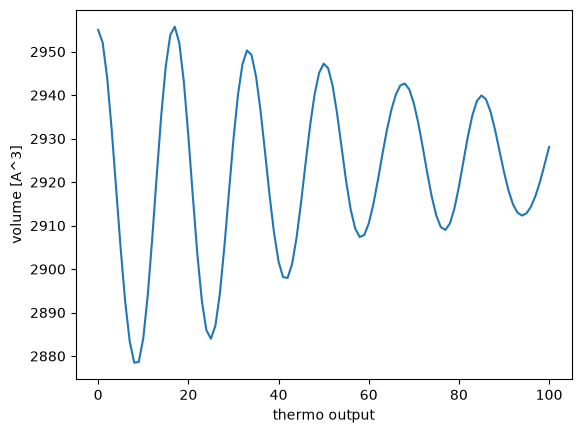

In [7]:
npt_engine = LammpsEngine(
    EngineInput=CalcInputMD(
        mode="NPT",
        thermostat="nose-hoover",
        temperature=300,
        thermostat_time_constant=100,  # fs
        pressure=1e5,  # Pa (1 bar)
        pressure_damping_timescale=1000,  # fs
        seed=42,
        time_step=1.0,  # fs
        n_print=10,
        n_ionic_steps=1000,
    ),
    working_directory=str(WORKDIR / "npt"),
    command=f"{lmp_cmd} -in in.lmp -log npt.log",
    lammps_log_filepath="npt.log",
    input_script_pair_style="eam/fs",
    path_to_model=EAM_POTENTIAL_PATH,
)
npt = calculate(structure=relaxed.final_structure, engine=npt_engine)
print("final E_pot [eV]:", npt.final_energy)
print("volume [A^3]:", relaxed.final_structure.get_volume(), "->", npt.final_structure.get_volume())

plt.plot([s.get_volume() for s in npt.structures])
plt.xlabel("thermo output")
plt.ylabel("volume [A^3]")
plt.show()

In [8]:
shutil.rmtree(WORKDIR, ignore_errors=True)